# Decipher on Nestorowa mHSC-E (BEELINE benchmark)

Runs Decipher on the **raw-count** Nestorowa mHSC-E RNA built by
`scripts/build_nestorowa_mhsc.py`, and saves `decipher_embeddings.npz`
(`z`: 10-D latent, `v`: 2-D visualization) into the dataset dir, where COMET's
`config` (the commented `NESTOROWA_MHSC_E` block) loads it. Mirrors
`pauldecipher.ipynb`. Run with the `decipher-env` kernel.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
import decipher as dc

DATA_DIR = "/home/elicanter/datasets/nestorowa_mhsc_e"

In [2]:
adata = sc.read_h5ad(f"{DATA_DIR}/Nestorowa_mHSC_E.h5ad")
# use raw integer counts for Decipher (matches the pauldecipher convention)
adata.X = adata.layers["raw_count_int"].copy()
adata

AnnData object with n_obs × n_vars = 1071 × 41382
    obs: 'PseudoTime', 'cell_type'
    uns: 'beeline_genes', 'beeline_lineage'
    layers: 'raw_count_int'

Epoch 81 (batch 15/15) | | train elbo: 59736.95 (last epoch: 59684.71) | val ll: 59025.28:   8%|▊         | 81/1000 [07:04<1:20:18,  5.24s/it]

2026-07-22 19:57:27,936 | INFO : Early stopping has been triggered.


2026-07-22 19:57:28,225 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.


2026-07-22 19:57:28,226 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.


2026-07-22 19:57:28,232 | INFO : Saving decipher model with run_id 2026-07-22-19-57-28-universal-feldspar-diameter.


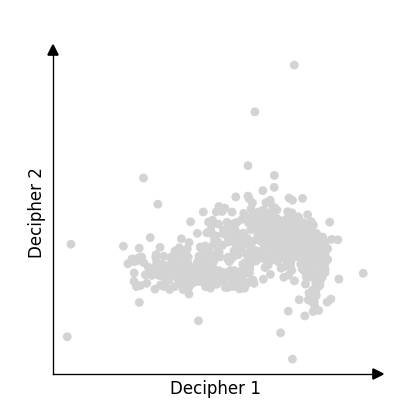

final val loss: 59025.27570093458
decipher_z: (1071, 10) | decipher_v: (1071, 2)


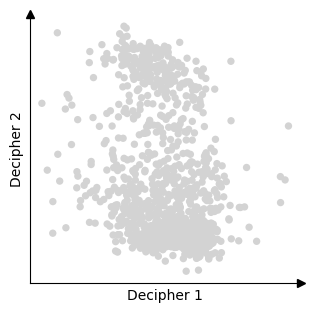

In [3]:
# no live plotting during training so the notebook executes headless cleanly
model, val_losses = dc.tl.decipher_train(adata, plot_every_k_epochs=-1)
print("final val loss:", float(val_losses[-1]))
print("decipher_z:", adata.obsm["decipher_z"].shape, "| decipher_v:", adata.obsm["decipher_v"].shape)

In [4]:
z = adata.obsm["decipher_z"]
v = adata.obsm["decipher_v"]
np.savez(f"{DATA_DIR}/decipher_embeddings.npz", z=z, v=v)
print("saved", f"{DATA_DIR}/decipher_embeddings.npz", "| z", z.shape, "v", v.shape)

saved /home/elicanter/datasets/nestorowa_mhsc_e/decipher_embeddings.npz | z (1071, 10) v (1071, 2)


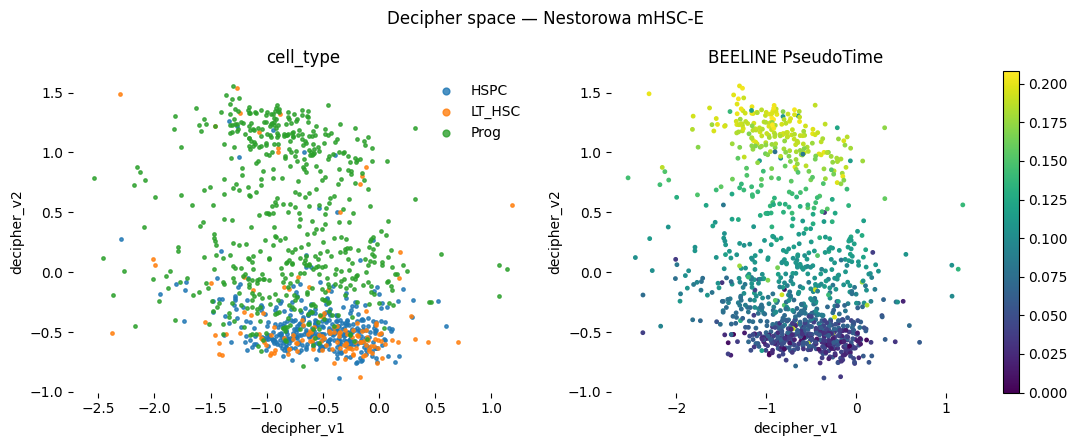

In [5]:
# Decipher v-space, colored by cell type and by BEELINE pseudotime
v = adata.obsm["decipher_v"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ct, sub in adata.obs.groupby("cell_type"):
    idx = adata.obs_names.get_indexer(sub.index)
    axes[0].scatter(v[idx, 0], v[idx, 1], s=6, label=ct, alpha=0.8)
axes[0].legend(frameon=False, markerscale=2); axes[0].set_title("cell_type")
sc0 = axes[1].scatter(v[:, 0], v[:, 1], s=6, c=adata.obs["PseudoTime"].values, cmap="viridis")
axes[1].set_title("BEELINE PseudoTime"); fig.colorbar(sc0, ax=axes[1])
for ax in axes:
    ax.set_xlabel("decipher_v1"); ax.set_ylabel("decipher_v2"); ax.set_frame_on(False)
fig.suptitle("Decipher space — Nestorowa mHSC-E")
fig.tight_layout()
fig.savefig(f"{DATA_DIR}/decipher_embedding.png", dpi=130, bbox_inches="tight")
plt.show()